In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression

from sklearn.model_selection import KFold, cross_validate, cross_val_predict

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

In [ ]:
base_path = "/content/drive/MyDrive/ML_Assignment/"

train_path = base_path + "Results/Outputs/final_preprocessed_train.csv"
test_path = base_path + "Results/Outputs/final_preprocessed_test.csv"

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

train_df.head()

Train shape: (1460, 76)
Test shape: (1459, 75)


,OverallQual,TotalSF,GrLivArea,GarageCars,TotalBathrooms,GarageArea,TotalBsmtSF,1stFlrSF,FullBath,TotRmsAbvGrd,...,Condition1,Alley,ExterCond,PoolQC,LotConfig,Functional,Heating,MiscFeature,Condition2,SalePrice
0,7,2566,1710,2,3.5,548,856,856,2,8,...,Norm,NaN,TA,NaN,Inside,Typ,GasA,NaN,Norm,208500
1,6,2524,1262,2,2.5,460,1262,1262,2,6,...,Feedr,NaN,TA,NaN,FR2,Typ,GasA,NaN,Norm,181500
2,7,2706,1786,2,3.5,608,920,920,2,6,...,Norm,NaN,TA,NaN,Inside,Typ,GasA,NaN,Norm,223500
3,7,2473,1717,3,2.0,642,756,961,1,7,...,Norm,NaN,TA,NaN,Corner,Typ,GasA,NaN,Norm,140000
4,8,3343,2198,3,3.5,836,1145,1145,2,9,...,Norm,NaN,TA,NaN,FR2,Typ,GasA,NaN,Norm,250000


# Separate Features and Target

In [ ]:
X = train_df.drop(columns=["SalePrice"])
y = train_df["SalePrice"]

print("X shape: ", X.shape)
print("Y shape: ", y.shape)

X shape:  (1460, 75)
Y shape:  (1460,)


In [ ]:
test_X = test_df.copy()
print("Test X shape: ", test_X.shape)

Test X shape:  (1459, 75)


In [ ]:
print("Same features: ", X.columns.tolist() == test_X.columns.tolist())

Same features:  True


# Log transformation

In [ ]:
y_log = np.log1p(y)

print("Original SalePrice skewness: ", y.skew())
print("Log SalePrice skewness: ", y_log.skew())

Original SalePrice skewness:  1.8828757597682129
Log SalePrice skewness:  0.12134661989685333


# Identify Numerical and Caategorical features

In [ ]:
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerrical Features: ", len(numeric_features))
print("Categorical Features: ", len(categorical_features))

Numerrical Features:  35
Categorical Features:  40


# Preprocessing Pipeline

In [ ]:
#Numerical Preprocesing

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy = 'median')),
    ("scaler", StandardScaler())
])

#Categorical Preprocessing

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

#combine both

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

Linear Regression Pipeline

In [ ]:
linear_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

5-fold cross validation

In [ ]:
kf = KFold(
    n_splits = 5,
    shuffle= True,
    random_state = 42
)

Run Linear Regression CV

In [ ]:
scoring = {
    "rmse": "neg_root_mean_squared_error",
    "mae" : "neg_mean_absolute_error",
    "r2" : "r2"
}

linear_cv = cross_validate(
    linear_pipeline,
    X,
    y_log,
    cv = kf,
    scoring = scoring,
    return_train_score = True
)

Display each Fold

In [ ]:
linear_results = pd.DataFrame({
    "Fold": range(1, 6),

    "Train_RMSE": -linear_cv["train_rmse"],
    "Validation_RMSE": -linear_cv["test_rmse"],

    "Train_MAE": -linear_cv["train_mae"],
    "Validation_MAE": -linear_cv["test_mae"],

    "Train_R2": linear_cv["train_r2"],
    "Validation_R2": linear_cv["test_r2"]
})

linear_results

,Fold,Train_RMSE,Validation_RMSE,Train_MAE,Validation_MAE,Train_R2,Validation_R2
0,1,0.095215,0.132777,0.066223,0.093267,0.940529,0.905527
1,2,0.097368,0.129769,0.069154,0.089447,0.940823,0.891638
2,3,0.092305,0.236654,0.066442,0.099442,0.948076,0.602405
3,4,0.091974,0.157152,0.065655,0.092331,0.945432,0.860369
4,5,0.099058,0.120759,0.069356,0.086258,0.940667,0.892502


# Calculate Final Baseline Results

In [ ]:
print("Linear Regression - 5 Fold CV")
print("--------------------------------")

print(
    "Mean Validation RMSE:",
    linear_results["Validation_RMSE"].mean()
)

print(
    "Mean Validation MAE:",
    linear_results["Validation_MAE"].mean()
)

print(
    "Mean Validation R²:",
    linear_results["Validation_R2"].mean()
)

Linear Regression - 5 Fold CV
--------------------------------
Mean Validation RMSE: 0.1554220253970417
Mean Validation MAE: 0.09214888817446643
Mean Validation R²: 0.8304884286909164


In [ ]:
print(
    "RMSE Standard Deviation:",
    linear_results["Validation_RMSE"].std()
)

print(
    "MAE Standard Deviation:",
    linear_results["Validation_MAE"].std()
)

print(
    "R² Standard Deviation:",
    linear_results["Validation_R2"].std()
)

RMSE Standard Deviation: 0.047365904010818256
MAE Standard Deviation: 0.004911294284669779
R² Standard Deviation: 0.12857940818534735


RMSE for each fold

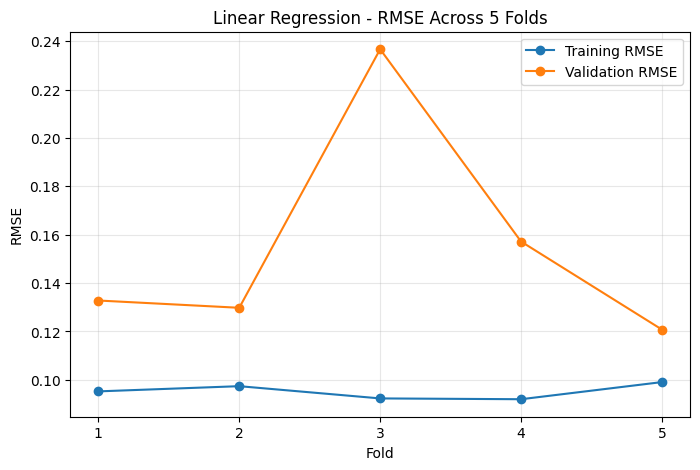

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    linear_results["Fold"],
    linear_results["Train_RMSE"],
    marker="o",
    label="Training RMSE"
)

plt.plot(
    linear_results["Fold"],
    linear_results["Validation_RMSE"],
    marker="o",
    label="Validation RMSE"
)

plt.xlabel("Fold")
plt.ylabel("RMSE")
plt.title("Linear Regression - RMSE Across 5 Folds")
plt.xticks(linear_results["Fold"])
plt.legend()
plt.grid(alpha=0.3)

plt.show()

Get Cross-Validated predictions

In [ ]:
y_log_pred = cross_val_predict(
    linear_pipeline,
    X,
    y_log,
    cv=kf
)

Actual vs Predicted

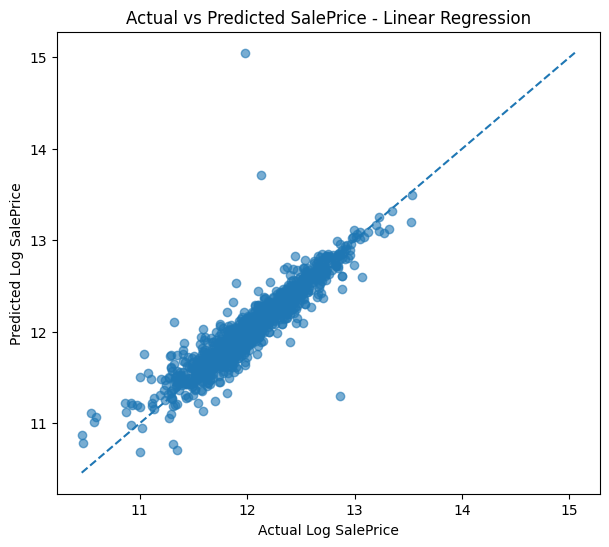

In [ ]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_log,
    y_log_pred,
    alpha=0.6
)

min_value = min(y_log.min(), y_log_pred.min())
max_value = max(y_log.max(), y_log_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Log SalePrice")
plt.ylabel("Predicted Log SalePrice")
plt.title("Actual vs Predicted SalePrice - Linear Regression")

plt.show()

Residual plot

In [ ]:
residuals = y_log - y_log_pred

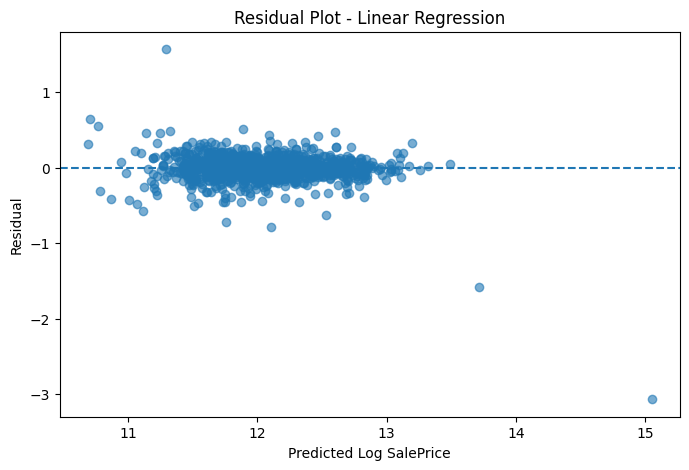

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    y_log_pred,
    residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Log SalePrice")
plt.ylabel("Residual")
plt.title("Residual Plot - Linear Regression")

plt.show()

Residual Distribution

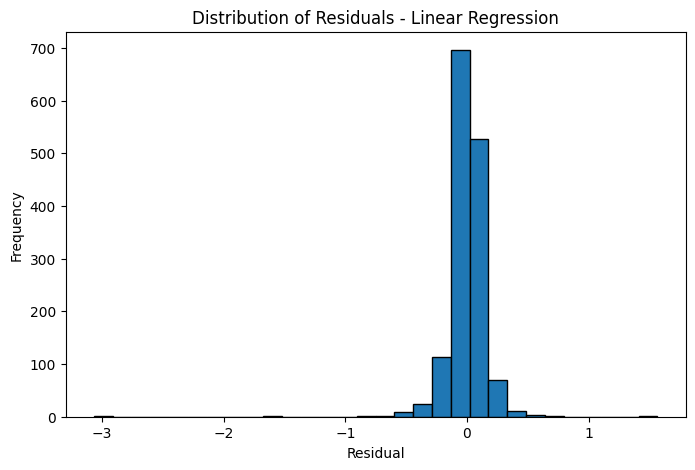

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(
    residuals,
    bins=30,
    edgecolor="black"
)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals - Linear Regression")

plt.show()

Overall cross-validated metrics

In [ ]:
overall_rmse = np.sqrt(
    mean_squared_error(y_log, y_log_pred)
)

overall_mae = mean_absolute_error(
    y_log,
    y_log_pred
)

overall_r2 = r2_score(
    y_log,
    y_log_pred
)

print("Overall Cross-Validated Performance")
print("-----------------------------------")
print("RMSE:", overall_rmse)
print("MAE:", overall_mae)
print("R²:", overall_r2)

Overall Cross-Validated Performance
-----------------------------------
RMSE: 0.16109261022383464
MAE: 0.09214888817446641
R²: 0.8372483013054589


In [ ]:
output_path = "/content/drive/MyDrive/ML_Assignment/Results/Outputs/"

linear_results.to_csv(
    output_path + "linear_regression_results.csv",
    index=False
)